# 02 · Expression — EMT transcription factors (unconditional final step)

Rendeiro 2020 CLL. Gate 1 was **NO-GO** (per-patient clonal archipelago, no shared continuous manifold, no embryonic module geography), so no trajectory / signature / correlation / module notebooks are produced. This unconditional expression step overlays the EMT-transcription-factor panel on the malignant manifold, following the reference categorical style: thresholded expressers coloured on a grey manifold.

**Panel rules (from prior-run lessons):** detection-gated (only TFs above a 3% detection floor), mesenchymal families beyond Snail/Zeb/Twist considered (FOXC1/2, PRRX1/2), and **VIM excluded** (it is not a transcription factor).

In [1]:
import os, sys
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, scanpy as sc, matplotlib.pyplot as plt
import scipy.sparse as sp
import warnings; warnings.filterwarnings('ignore')

In [2]:
name = os.path.split(os.getcwd())[1]
pth  = os.path.join('..', '..', '..', '..')
pth_in  = os.path.join(pth,'data','cancer', 'vertebrate', 'CCCA', 'claude','Hematologic', name)
pth_fig = os.path.join(pth,'figures', 'mesencontext', 'claude','Hematologic', name)
adata = sc.read_h5ad(os.path.join(pth_in,'processed.h5ad'))
adata

AnnData object with n_obs × n_vars = 18598 × 14889
    obs: 'sample', 'patient', 'timepoint', 'cell_type', 'complexity', 'celltype', 'S_score', 'G2M_score', 'phase', 'cycling_score', 'leiden', 'Gast', 'pSom', 'Crest', 'RND'
    var: 'n_cells', 'm', 'v', 'n_obs', 'res', 'lp', 'lpa', 'qv', 'highly_variable'
    uns: 'gate1', 'leiden', 'leiden_colors', 'log1p', 'neighbors', 'patient_colors', 'pca', 'phase_colors', 'sample_colors', 'umap'
    obsm: 'X_pca', 'X_pca_harmony', 'X_umap'
    varm: 'PCs'
    obsp: 'connectivities', 'distances'

### Detection-gate the EMT-TF panel
Keep only transcription factors expressed in ≥3% of cells.

In [3]:
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']  # VIM excluded (not a TF)
def col(g):
    x=adata[:,g].X; return np.asarray(x.todense()).ravel() if sp.issparse(x) else np.asarray(x).ravel()
print(f"{'gene':8s}{'in_var':>8s}{'pct>0':>9s}{'mean':>9s}")
stats={}
for g in panel:
    if g in adata.var_names:
        x=col(g); pct=float((x>0).mean()*100); stats[g]=pct
        print(f'{g:8s}{"Y":>8s}{pct:9.2f}{float(x.mean()):9.4f}')
    else:
        print(f'{g:8s}{"-":>8s}{"absent":>9s}')
shown=[g for g in panel if stats.get(g,0)>=3.0]
print('\nEMT-TFs above 3% detection floor:', [f'{g} ({stats[g]:.1f}%)' for g in shown])

gene      in_var    pct>0     mean
SNAI1          Y     0.05   0.0002
SNAI2          -   absent
ZEB1           Y     3.81   0.0199
ZEB2           Y    12.34   0.0684
TWIST1         -   absent
TWIST2         -   absent
FOXC1          Y     0.05   0.0003
FOXC2          -   absent
PRRX1          Y     0.02   0.0001
PRRX2          -   absent

EMT-TFs above 3% detection floor: ['ZEB1 (3.8%)', 'ZEB2 (12.3%)']


Only **ZEB2** and **ZEB1** clear the floor; SNAI1/FOXC1/PRRX1 are near-silent and SNAI2/TWIST1/TWIST2/FOXC2/PRRX2 are absent — canonical mesenchymal TFs are largely silent in this lymphoid malignancy, consistent with all prior attempts.

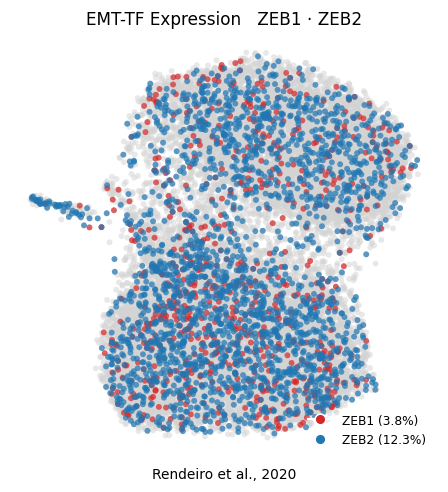

In [4]:
# categorical overlay: thresholded expressers on a grey manifold (reference style, consistent orientation)
colors={'ZEB2':'tab:blue','ZEB1':'tab:red'}
fig,ax=plt.subplots(1,1,figsize=(5,5))
sc.pl.umap(adata,size=60,alpha=.5,frameon=False,show=False,ax=ax,na_color='lightgrey')
for g in shown:
    sub=adata[col(g)>0].copy()
    sc.pl.umap(sub,na_color=colors[g],size=60,alpha=.7,frameon=False,show=False,ax=ax)
ax.invert_yaxis(); ax.invert_xaxis()
ax.set_title('EMT-TF Expression   ' + ' · '.join(shown), size=11)
ax.text(.5,-.05,'Rendeiro et al., 2020',ha='center',transform=ax.transAxes,fontsize=9)
from matplotlib.lines import Line2D
leg=[Line2D([0],[0],marker='o',color='w',markerfacecolor=colors[g],markersize=7,label=f'{g} ({stats[g]:.1f}%)') for g in shown]
ax.legend(handles=leg,frameon=False,loc='lower right',fontsize=8)
fig.savefig(os.path.join(pth_fig,'expression.pdf'),bbox_inches='tight'); plt.show()

**Result.** The two detectable EMT-TFs (ZEB2, ZEB1) are scattered uniformly across the manifold with no spatial organisation — consistent with the Gate 1 NO-GO: there is no cell-state axis along which an EMT programme could be arranged. No EMT transition is supported in this CLL malignant compartment.